### 0. Clone GitHub Repository
Run the cell below to clone the repository containing the `src` folder into this Colab environment.
* Replace the URL with your repository's URL.
* If your `src` folder is inside a subdirectory, make sure to change directory `%cd` into that folder after cloning.

In [3]:
# Clone the specific project repository
!git clone https://github.com/manichandukore/ChurnGuard-ML.git

# List files to verify 'src' exists in the current directory
!ls -la ChurnGuard-ML

Cloning into 'ChurnGuard-ML'...
remote: Enumerating objects: 70, done.
remote: Counting objects: 100% (70/70), done.
remote: Compressing objects: 100% (57/57), done.
remote: Total 70 (delta 9), reused 21 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (70/70), 1.14 MiB | 4.29 MiB/s, done.
Resolving deltas: 100% (9/9), done.
total 192
drwxr-xr-x 6 root root   4096 Oct 28 08:55 .
drwxr-xr-x 1 root root   4096 Oct 28 08:55 ..
drwxr-xr-x 8 root root   4096 Oct 28 08:55 customer-churn-ml
-rw-r--r-- 1 root root    445 Oct 28 08:55 .env.example
drwxr-xr-x 8 root root   4096 Oct 28 08:55 .git
-rw-r--r-- 1 root root     81 Oct 28 08:55 .gitignore
-rw-r--r-- 1 root root   1006 Oct 28 08:55 index.html
-rw-r--r-- 1 root root    373 Oct 28 08:55 metadata.json
-rw-r--r-- 1 root root    900 Oct 28 08:55 package.json
-rw-r--r-- 1 root root 135148 Oct 28 08:55 package-lock.json
drwxr-xr-x 3 root root   4096 Oct 28 08:55 public
-rw-r--r-- 1 root root   8177 Oct 28 08:55 server.ts
drwxr-xr-x 3 

## Task 1: Implement model persistence techniques for saving, loading, and reusing trained machine learning and deep learning models.

### 1.1 Install/import libraries

In [5]:
%pip -q install pandas numpy scikit-learn matplotlib joblib

import os
import sys
import json
import time
import pickle
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              StackingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
DATA_DIR = "data"
MODEL_DIR = "models"
RESULT_DIR = "results"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# Make the cloned project directory and its nested module directory importable
repo_path = os.path.abspath("ChurnGuard-ML/customer-churn-ml")
if repo_path not in sys.path:
    sys.path.insert(0, repo_path)
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

from src.data_preprocessing import prepare_train_test
from src.feature_engineering import ChurnFeatureEngineer
from src.train import create_preprocessor

print("Libraries imported. scikit-learn version:", sklearn.__version__)

Libraries imported. scikit-learn version: 1.6.1


### 1.2 Load the exact project dataset

In [8]:
import shutil

CSV_PATH = os.path.join(DATA_DIR, "dataset.csv")
CLONED_CSV_PATH = "ChurnGuard-ML/customer-churn-ml/data/dataset.csv"

# If it doesn't exist in data/, check if we can copy it from the cloned repo
if not os.path.exists(CSV_PATH) and os.path.exists(CLONED_CSV_PATH):
    print("Copying dataset from cloned repository...")
    shutil.copy(CLONED_CSV_PATH, CSV_PATH)

if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    print("Loaded existing dataset:", CSV_PATH)
else:
    # Fallback upload option
    print("Dataset not found. Please upload dataset.csv:")
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        csv_name = next(iter(uploaded))
        df = pd.read_csv(csv_name)
        df.to_csv(CSV_PATH, index=False)
    else:
        raise FileNotFoundError("No file was uploaded.")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head(5))

Copying dataset from cloned repository...
Loaded existing dataset: data/dataset.csv
Dataset shape: (7043, 21)
Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 1.3 Data cleaning and stratified train/test split

In [9]:
required_columns = ["customerID", "tenure", "MonthlyCharges", "TotalCharges",
                    "Contract", "InternetService", "PaymentMethod", "Churn"]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing expected project columns: {missing_columns}")

# prepare_train_test(): drops customerID, fixes TotalCharges, encodes Churn (Yes=1, No=0),
# and performs an 80/20 stratified split BEFORE any transformation (prevents data leakage)
X_train, X_test, y_train, y_test = prepare_train_test(df, test_size=0.2,
                                                      random_state=RANDOM_STATE)

print("Rows:", len(df))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Features:", X_train.columns.tolist())
print("Churn rate (train): %.4f | Churn rate (test): %.4f" % (y_train.mean(), y_test.mean()))

Rows: 7043
Training rows: 5634
Testing rows: 1409
Features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']
Churn rate (train): 0.2654 | Churn rate (test): 0.2654


### 1.4 Train and save the Random Forest pipeline

In [10]:
def make_pipeline(classifier):
    # Full pipeline: feature engineering -> preprocessing -> classifier
    return Pipeline(steps=[
        ("feature_engineer", ChurnFeatureEngineer()),
        ("preprocessor", create_preprocessor()),
        ("classifier", classifier)
    ])

persistence_pipeline = make_pipeline(
    RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
)

print("Training Random Forest pipeline...")
persistence_pipeline.fit(X_train, y_train)

model_path = os.path.join(MODEL_DIR, "exp10_churn_rf_model.pkl")
joblib.dump(persistence_pipeline, model_path)
print("Model saved to:", model_path)

Training Random Forest pipeline...
Model saved to: models/exp10_churn_rf_model.pkl


### 1.5 Load and reuse the saved model

In [11]:
loaded_pipeline = joblib.load(model_path)

proba_before_save = persistence_pipeline.predict_proba(X_test)[:, 1]
proba_after_load = loaded_pipeline.predict_proba(X_test)[:, 1]

same_predictions = np.allclose(proba_before_save, proba_after_load)
print("Persistence verification:", "PASSED" if same_predictions else "FAILED")
print("Maximum prediction difference:",
      float(np.max(np.abs(proba_before_save - proba_after_load))))

display(pd.DataFrame({
    "Actual churn (1=Yes)": y_test.iloc[:10].to_numpy(),
    "Churn probability after loading model": proba_after_load[:10].round(4),
    "Predicted class": loaded_pipeline.predict(X_test.iloc[:10])
}))

Persistence verification: PASSED
Maximum prediction difference: 0.0


,Actual churn (1=Yes),Churn probability after loading model,Predicted class
0,0,0.06,0
1,0,0.83,1
2,0,0.08,0
3,0,0.27,0
4,0,0.06,0
5,0,0.49,0
6,0,0.39,0
7,0,0.15,0
8,0,0.03,0
9,1,0.43,0


### 1.6 Compare persistence techniques: joblib vs pickle (vs compressed joblib)

In [12]:
formats = {
    "joblib (.pkl)":          lambda obj, p: joblib.dump(obj, p),
    "joblib compressed (.gz)": lambda obj, p: joblib.dump(obj, p, compress=3),
    "pickle (.pickle)":       lambda obj, p: pickle.dump(obj, open(p, "wb")),
}
loaders = {
    "joblib (.pkl)":          lambda p: joblib.load(p),
    "joblib compressed (.gz)": lambda p: joblib.load(p),
    "pickle (.pickle)":       lambda p: pickle.load(open(p, "rb")),
}
extensions = {"joblib (.pkl)": "demo_joblib.pkl",
              "joblib compressed (.gz)": "demo_joblib_compressed.gz",
              "pickle (.pickle)": "demo_pickle.pickle"}

rows = []
for name, saver in formats.items():
    path = os.path.join(MODEL_DIR, extensions[name])
    t0 = time.perf_counter(); saver(persistence_pipeline, path); save_t = time.perf_counter() - t0
    t0 = time.perf_counter(); obj = loaders[name](path);          load_t = time.perf_counter() - t0
    ok = np.allclose(obj.predict_proba(X_test)[:, 1], proba_before_save)
    rows.append({"Technique": name,
                 "File size (KB)": os.path.getsize(path) / 1024,
                 "Save time (s)": save_t,
                 "Load time (s)": load_t,
                 "Predictions identical": ok})

persistence_df = pd.DataFrame(rows)
display(persistence_df.round(4))
persistence_df.to_csv(os.path.join(RESULT_DIR, "persistence_comparison.csv"), index=False)

,Technique,File size (KB),Save time (s),Load time (s),Predictions identical
0,joblib (.pkl),16386.5732,0.0548,0.0552,True
1,joblib compressed (.gz),2872.3281,0.2710,0.1084,True
2,pickle (.pickle),16374.4355,0.0190,0.0136,True


### 1.7 Persist a neural-network (deep learning) model and its metadata

In [13]:
# Multi-layer perceptron (feed-forward neural network) inside the same pipeline
nn_pipeline = make_pipeline(
    MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", max_iter=300,
                  early_stopping=True, random_state=RANDOM_STATE)
)
nn_pipeline.fit(X_train, y_train)

nn_path = os.path.join(MODEL_DIR, "exp10_churn_mlp_model.pkl")
joblib.dump(nn_pipeline, nn_path)

nn_loaded = joblib.load(nn_path)
nn_proba = nn_loaded.predict_proba(X_test)[:, 1]
print("Neural network saved to:", nn_path)
print("Reloaded NN ROC-AUC: %.4f" % roc_auc_score(y_test, nn_proba))

# Persist metadata (versions + feature list) so the model can be reproduced later
metadata = {
    "model_file": model_path,
    "algorithm": "RandomForestClassifier",
    "sklearn_version": sklearn.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "feature_columns": X_train.columns.tolist(),
    "target": "Churn (1 = churned)",
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "test_roc_auc": float(roc_auc_score(y_test, proba_after_load)),
}
meta_path = os.path.join(MODEL_DIR, "exp10_model_metadata.json")
with open(meta_path, "w") as f:
    json.dump(metadata, f, indent=4)
print("Metadata saved to:", meta_path)
print(json.dumps(metadata, indent=4))

Neural network saved to: models/exp10_churn_mlp_model.pkl
Reloaded NN ROC-AUC: 0.8465
Metadata saved to: models/exp10_model_metadata.json
{
    "model_file": "models/exp10_churn_rf_model.pkl",
    "algorithm": "RandomForestClassifier",
    "sklearn_version": "1.6.1",
    "numpy_version": "2.1.3",
    "pandas_version": "2.2.3",
    "feature_columns": [
        "gender",
        "SeniorCitizen",
        "Partner",
        "Dependents",
        "tenure",
        "PhoneService",
        "MultipleLines",
        "InternetService",
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies",
        "Contract",
        "PaperlessBilling",
        "PaymentMethod",
        "MonthlyCharges",
        "TotalCharges"
    ],
    "target": "Churn (1 = churned)",
    "train_rows": 5634,
    "test_rows": 1409,
    "test_roc_auc": 0.8232826991139013
}


## Task 2: Analyze model performance through monitoring, optimization, and comparative evaluation techniques

### 2.1 Train and compare the project models

In [14]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1,
                                                    random_state=RANDOM_STATE),
    "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300,
                                          early_stopping=True, random_state=RANDOM_STATE),
}

comparison_rows = []
fitted_pipelines = {}

for model_name, estimator in models.items():
    print(f"Training: {model_name}")
    pipeline = make_pipeline(estimator)

    t0 = time.perf_counter()
    pipeline.fit(X_train, y_train)
    train_time = time.perf_counter() - t0

    t0 = time.perf_counter()
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    predict_time = time.perf_counter() - t0

    fitted_pipelines[model_name] = pipeline
    comparison_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "Train time (s)": train_time,
        "Predict time (s)": predict_time,
    })

results_df = pd.DataFrame(comparison_rows).sort_values("ROC_AUC", ascending=False).reset_index(drop=True)
results_path = os.path.join(RESULT_DIR, "model_comparison_results.csv")
results_df.to_csv(results_path, index=False)
display(results_df.round(4))
print("Exact results saved to:", results_path)

Training: Logistic Regression
Training: Random Forest
Training: Gradient Boosting
Training: Neural Network (MLP)


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Train time (s),Predict time (s)
0,Logistic Regression,0.8062,0.6700,0.5321,0.5931,0.8466,0.2612,0.1670
1,Neural Network (MLP),0.7942,0.6207,0.5775,0.5983,0.8465,1.2198,0.2900
2,Gradient Boosting,0.7977,0.6540,0.5053,0.5701,0.8437,2.0967,0.1295
3,Random Forest,0.7871,0.6259,0.4920,0.5509,0.8233,0.9876,0.2212


Exact results saved to: results/model_comparison_results.csv


### 2.2 Monitor stability with 5-fold stratified cross-validation

In [15]:
from sklearn.model_selection import cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for model_name, estimator in models.items():
    scores = cross_val_score(make_pipeline(clone(estimator)), X_train, y_train,
                             cv=cv, scoring="roc_auc", n_jobs=-1)
    cv_rows.append({"Model": model_name,
                    "CV mean ROC-AUC": scores.mean(),
                    "CV std": scores.std()})

cv_df = pd.DataFrame(cv_rows).sort_values("CV mean ROC-AUC", ascending=False).reset_index(drop=True)
cv_df.to_csv(os.path.join(RESULT_DIR, "cross_validation_results.csv"), index=False)
display(cv_df.round(4))
print("Interpretation: a small standard deviation means the model's performance is stable across folds.")

,Model,CV mean ROC-AUC,CV std
0,Gradient Boosting,0.8482,0.0127
1,Logistic Regression,0.8481,0.0120
2,Neural Network (MLP),0.8340,0.0146
3,Random Forest,0.8254,0.0101


Interpretation: a small standard deviation means the model's performance is stable across folds.


### 2.3 Plot Accuracy, F1-score, and ROC-AUC comparisons

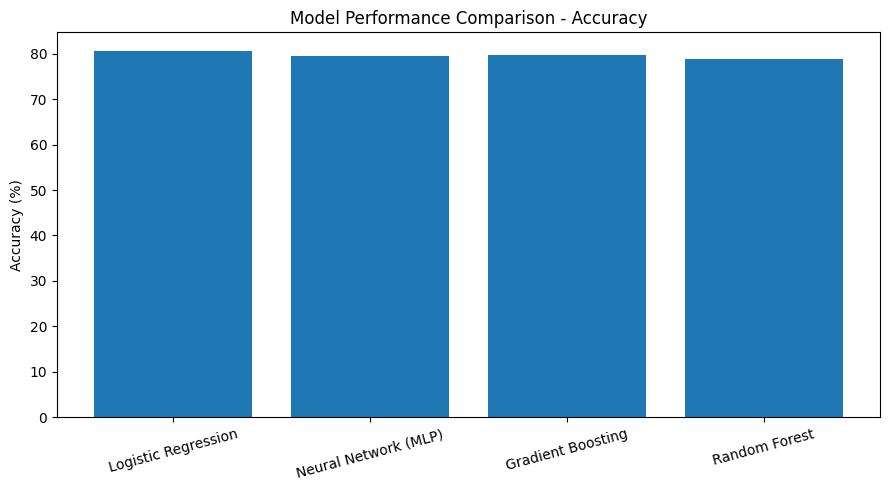

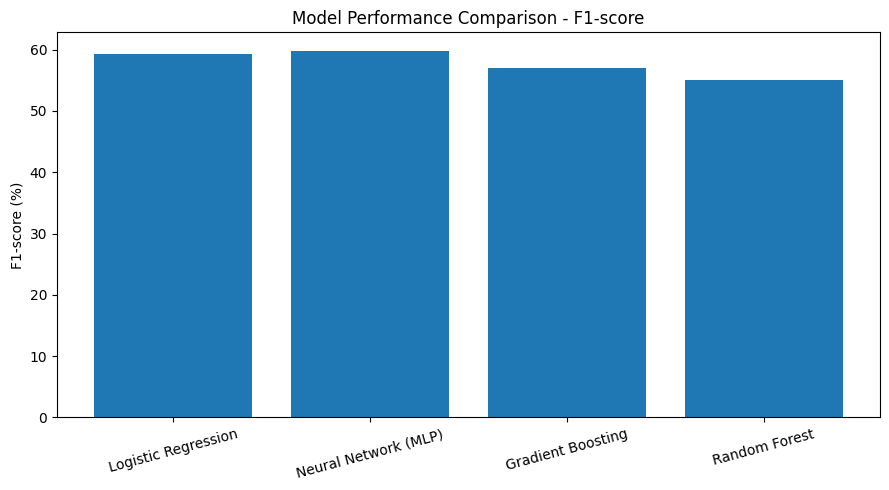

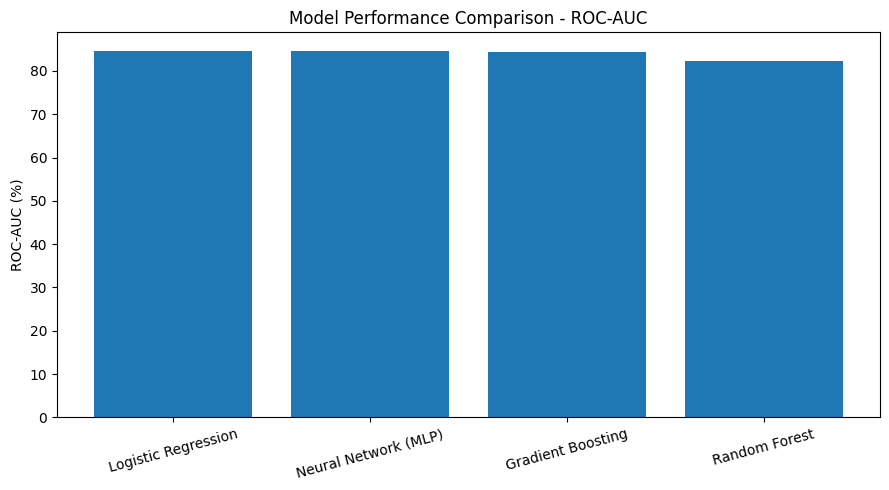

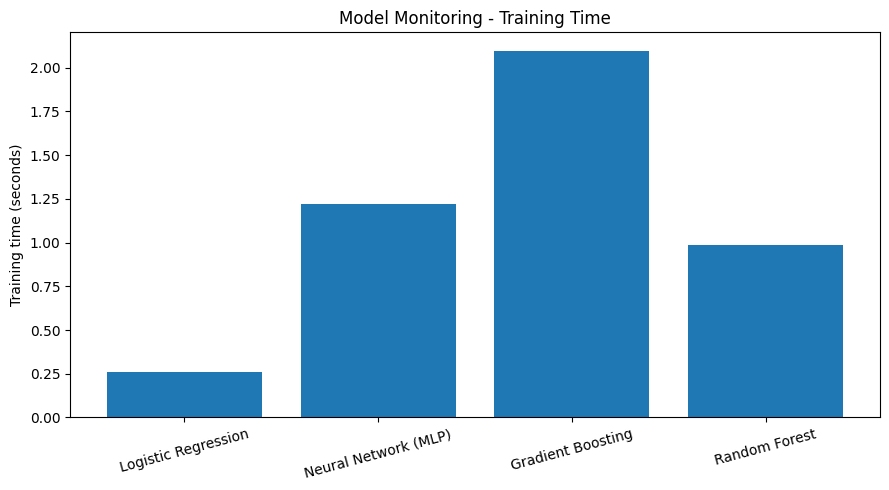

In [16]:
# Accuracy comparison
plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["Accuracy"] * 100)
plt.ylabel("Accuracy (%)")
plt.title("Model Performance Comparison - Accuracy")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(RESULT_DIR, "accuracy_comparison.png"), dpi=200)
plt.show()

# F1-score comparison
plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["F1"] * 100)
plt.ylabel("F1-score (%)")
plt.title("Model Performance Comparison - F1-score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(RESULT_DIR, "f1_comparison.png"), dpi=200)
plt.show()

# ROC-AUC comparison
plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["ROC_AUC"] * 100)
plt.ylabel("ROC-AUC (%)")
plt.title("Model Performance Comparison - ROC-AUC")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(RESULT_DIR, "roc_auc_comparison.png"), dpi=200)
plt.show()

# Training time (resource monitoring)
plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["Train time (s)"])
plt.ylabel("Training time (seconds)")
plt.title("Model Monitoring - Training Time")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(RESULT_DIR, "training_time_comparison.png"), dpi=200)
plt.show()

### 2.4 Inspect the best model: ROC curves and confusion matrix

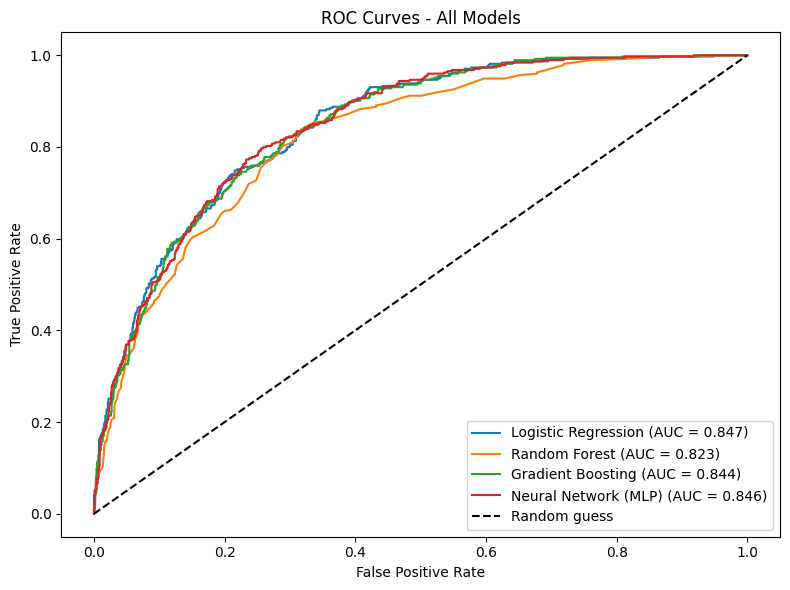

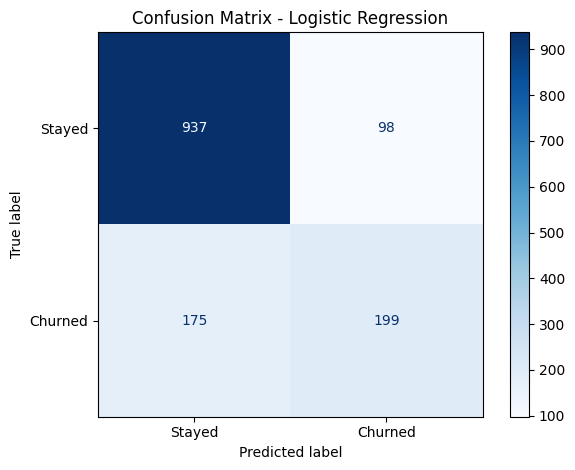

Highest ROC-AUC model: Logistic Regression
Interpretation: higher ROC-AUC/F1 mean better churn separation; recall shows how many real churners are caught.


In [17]:
best_name = results_df.iloc[0]["Model"]          # highest ROC-AUC
best_pipeline = fitted_pipelines[best_name]
best_proba = best_pipeline.predict_proba(X_test)[:, 1]
best_predictions = best_pipeline.predict(X_test)

# ROC curves of all models
plt.figure(figsize=(8, 6))
for name, pipe in fitted_pipelines.items():
    fpr, tpr, _ = roc_curve(y_test, pipe.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1]):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - All Models")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULT_DIR, "roc_curves_comparison.png"), dpi=200)
plt.show()

# Confusion matrix of the best model
ConfusionMatrixDisplay(confusion_matrix(y_test, best_predictions),
                       display_labels=["Stayed", "Churned"]).plot(cmap="Blues")
plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.savefig(os.path.join(RESULT_DIR, "confusion_matrix_best_model.png"), dpi=200)
plt.show()

print("Highest ROC-AUC model:", best_name)
print("Interpretation: higher ROC-AUC/F1 mean better churn separation; recall shows how many real churners are caught.")

## Task 3: Develop advanced predictive learning workflows integrating multiple machine learning techniques for intelligent decision-making

### 3.1 Run GridSearchCV (hyperparameter optimization)

In [18]:
tuning_pipeline = make_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE))

param_grid = {
    "classifier__n_estimators": [100, 150],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__max_depth": [3, 4],
    "classifier__subsample": [0.8, 1.0],
}

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
    verbose=1
)

print("Starting hyperparameter tuning. This may take a few minutes.")
grid_search.fit(X_train, y_train)

optimized_model = grid_search.best_estimator_
print("Best parameters:")
print(grid_search.best_params_)
print("Best cross-validation ROC-AUC:", round(grid_search.best_score_, 4))

Starting hyperparameter tuning. This may take a few minutes.
Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best parameters:
{'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__n_estimators': 100, 'classifier__subsample': 1.0}
Best cross-validation ROC-AUC: 0.8488


### 3.2 Evaluate the optimized model

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Optimized Gradient Boosting,0.8034,0.6678,0.516,0.5822,0.8467


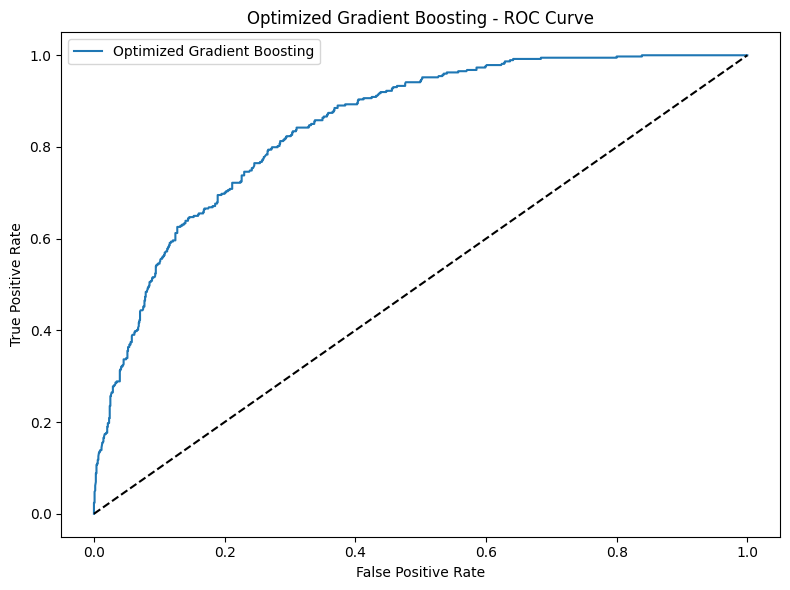

In [19]:
def evaluate(model, name):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    return {"Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0),
            "ROC_AUC": roc_auc_score(y_test, proba)}

optimized_metrics_df = pd.DataFrame([evaluate(optimized_model, "Optimized Gradient Boosting")])
display(optimized_metrics_df.round(4))
metrics_path = os.path.join(RESULT_DIR, "optimized_model_metrics.csv")
optimized_metrics_df.to_csv(metrics_path, index=False)

fpr, tpr, _ = roc_curve(y_test, optimized_model.predict_proba(X_test)[:, 1])
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label="Optimized Gradient Boosting")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Optimized Gradient Boosting - ROC Curve")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULT_DIR, "roc_optimized.png"), dpi=200)
plt.show()

### 3.3 Integrated workflow: stacking ensemble (Logistic Regression + Random Forest + tuned Gradient Boosting)

In [20]:
tuned_gb_params = {k.replace("classifier__", ""): v for k, v in grid_search.best_params_.items()}

stacking_model = make_pipeline(
    StackingClassifier(
        estimators=[
            ("lr", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
            ("rf", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
            ("gb", GradientBoostingClassifier(random_state=RANDOM_STATE, **tuned_gb_params)),
        ],
        final_estimator=LogisticRegression(max_iter=1000),
        cv=3,
        n_jobs=-1
    )
)

print("Training stacking ensemble...")
stacking_model.fit(X_train, y_train)

final_compare = pd.DataFrame([
    evaluate(fitted_pipelines["Gradient Boosting"], "Baseline Gradient Boosting"),
    evaluate(optimized_model, "Optimized Gradient Boosting"),
    evaluate(stacking_model, "Stacking Ensemble"),
]).sort_values("ROC_AUC", ascending=False).reset_index(drop=True)

display(final_compare.round(4))
final_compare.to_csv(os.path.join(RESULT_DIR, "final_model_comparison.csv"), index=False)

final_name = final_compare.iloc[0]["Model"]
final_model = {"Baseline Gradient Boosting": fitted_pipelines["Gradient Boosting"],
               "Optimized Gradient Boosting": optimized_model,
               "Stacking Ensemble": stacking_model}[final_name]
print("Selected final model:", final_name)

Training stacking ensemble...


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Stacking Ensemble,0.8041,0.6713,0.5134,0.5818,0.8479
1,Optimized Gradient Boosting,0.8034,0.6678,0.5160,0.5822,0.8467
2,Baseline Gradient Boosting,0.7977,0.6540,0.5053,0.5701,0.8437


Selected final model: Stacking Ensemble


### 3.4 Decision threshold optimization (intelligent decision-making)

Best decision threshold (max F1 on training OOF): 0.25


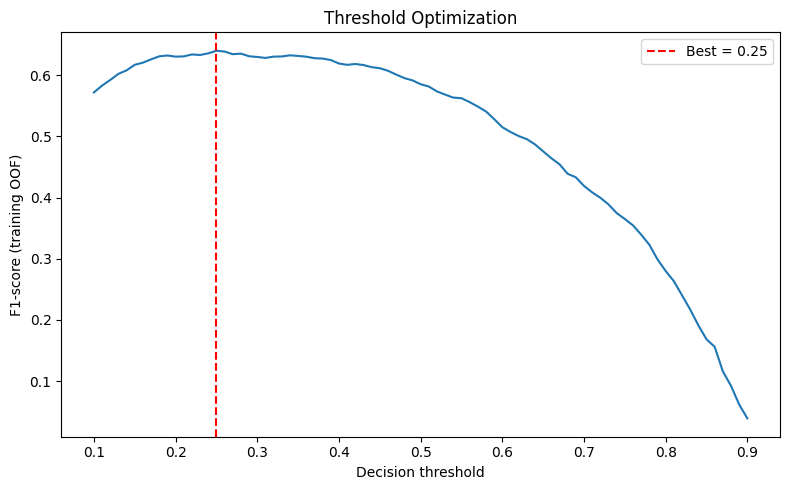

,Setting,Accuracy,Precision,Recall,F1
0,Default threshold (0.50),0.8041,0.6713,0.5134,0.5818
1,Optimized threshold (0.25),0.7637,0.5393,0.7513,0.6279


In [21]:
# The default threshold (0.5) is not ideal for imbalanced churn data.
# Choose the threshold on TRAINING out-of-fold predictions (no test-set leakage).
oof_proba = cross_val_predict(clone(final_model), X_train, y_train, cv=3,
                              method="predict_proba", n_jobs=-1)[:, 1]

thresholds = np.arange(0.10, 0.91, 0.01)
f1_scores = [f1_score(y_train, (oof_proba >= t).astype(int)) for t in thresholds]
best_threshold = float(thresholds[int(np.argmax(f1_scores))])
print("Best decision threshold (max F1 on training OOF): %.2f" % best_threshold)

plt.figure(figsize=(8, 5))
plt.plot(thresholds, f1_scores)
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Best = {best_threshold:.2f}")
plt.xlabel("Decision threshold")
plt.ylabel("F1-score (training OOF)")
plt.title("Threshold Optimization")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULT_DIR, "threshold_optimization.png"), dpi=200)
plt.show()

test_proba = final_model.predict_proba(X_test)[:, 1]
rows = []
for label, t in [("Default threshold (0.50)", 0.5), (f"Optimized threshold ({best_threshold:.2f})", best_threshold)]:
    pred = (test_proba >= t).astype(int)
    rows.append({"Setting": label,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})
threshold_df = pd.DataFrame(rows)
display(threshold_df.round(4))
threshold_df.to_csv(os.path.join(RESULT_DIR, "threshold_comparison.csv"), index=False)

### 3.5 Save, reload, and use the optimized model

In [22]:
optimized_model_path = os.path.join(MODEL_DIR, "exp10_churn_model_optimized.pkl")
joblib.dump({"model": final_model,
             "threshold": best_threshold,
             "model_name": final_name,
             "sklearn_version": sklearn.__version__}, optimized_model_path)
print("Optimized model saved to:", optimized_model_path)

# Reload and verify
bundle = joblib.load(optimized_model_path)
reloaded_model, reloaded_threshold = bundle["model"], bundle["threshold"]
same = np.allclose(final_model.predict_proba(X_test)[:, 1],
                   reloaded_model.predict_proba(X_test)[:, 1])
print("Persistence verification:", "PASSED" if same else "FAILED")

Optimized model saved to: models/exp10_churn_model_optimized.pkl
Persistence verification: PASSED


### 3.6 Use the reloaded model for customer-level decisions

In [23]:
def retention_decision(customers: pd.DataFrame) -> pd.DataFrame:
    # Convert churn probability into a risk level and a recommended business action
    proba = reloaded_model.predict_proba(customers)[:, 1]
    out = pd.DataFrame({"Churn probability": proba.round(4)}, index=customers.index)
    out["Prediction"] = np.where(proba >= reloaded_threshold, "Will churn", "Will stay")
    # High: at/above the optimized threshold; Medium: at/above half of it; Low: below
    out["Risk level"] = np.select([proba >= reloaded_threshold, proba >= reloaded_threshold / 2],
                                  ["High", "Medium"], default="Low")
    actions = {"Low": "No action - keep monitoring",
               "Medium": "Send loyalty offer / satisfaction survey",
               "High": "Priority call + contract-upgrade discount"}
    out["Recommended action"] = out["Risk level"].map(actions)
    return out

# Reuse the model on 8 unseen test customers
sample_customers = X_test.head(8)
decision_table = retention_decision(sample_customers)
decision_table.insert(0, "Actual churn", y_test.head(8).map({1: "Yes", 0: "No"}))
display(decision_table)

# Predict for a brand-new customer record
new_customer = pd.DataFrame([{
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No",
    "tenure": 2, "PhoneService": "Yes", "MultipleLines": "No",
    "InternetService": "Fiber optic", "OnlineSecurity": "No", "OnlineBackup": "No",
    "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "No",
    "StreamingMovies": "No", "Contract": "Month-to-month", "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check", "MonthlyCharges": 70.7, "TotalCharges": 151.65
}])
display(retention_decision(new_customer))
decision_table.to_csv(os.path.join(RESULT_DIR, "retention_decisions_sample.csv"))

,Actual churn,Churn probability,Prediction,Risk level,Recommended action
437,No,0.0692,Will stay,Low,No action - keep monitoring
2280,No,0.8157,Will churn,High,Priority call + contract-upgrade discount
2235,No,0.0769,Will stay,Low,No action - keep monitoring
4460,No,0.2980,Will churn,High,Priority call + contract-upgrade discount
3761,No,0.0643,Will stay,Low,No action - keep monitoring
5748,No,0.5843,Will churn,High,Priority call + contract-upgrade discount
3568,No,0.3897,Will churn,High,Priority call + contract-upgrade discount
2976,No,0.1004,Will stay,Low,No action - keep monitoring


,Churn probability,Prediction,Risk level,Recommended action
0,0.7698,Will churn,High,Priority call + contract-upgrade discount


### Conclusion
* Trained pipelines (feature engineering + preprocessing + model) were saved with `joblib`/`pickle` and reloaded with identical predictions.
* Four models were compared on Accuracy, Precision, Recall, F1, ROC-AUC, 5-fold CV stability, and training time.
* GridSearchCV tuned Gradient Boosting; a stacking ensemble combined three algorithms.
* Threshold optimization and a risk-based action table turn predictions into retention decisions.